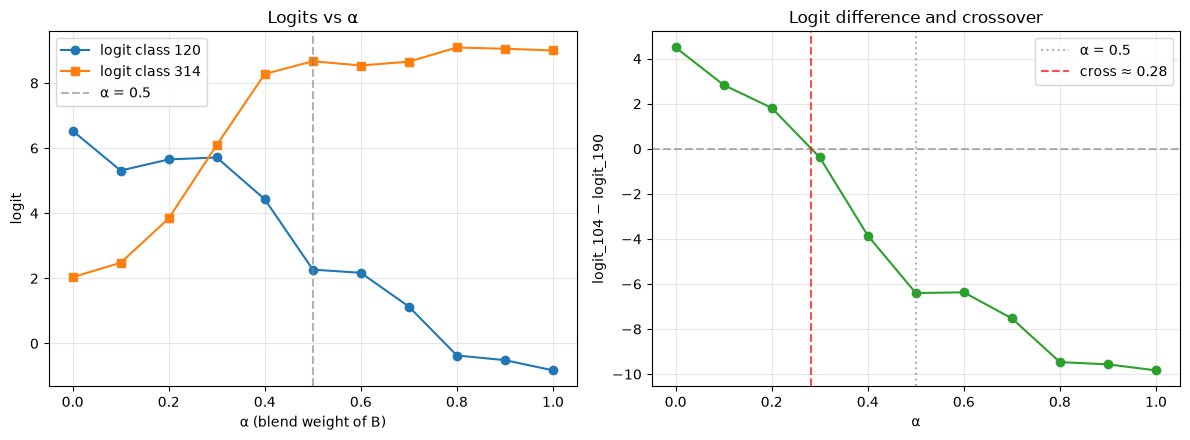

In [1]:
import numpy as np
import matplotlib.pyplot as plt

alpha = np.array([0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0])
# cls1_points  = np.array([8.900482,8.819244,8.344234,8.209675,7.928754, 7.719523,6.735669,6.511984,4.417964,-0.144907,-0.346204])
# cls2_points  = np.array([-0.297509,-0.285845,0.551345,3.904553,6.492804, 6.220845,4.484468,8.146927,7.826475,8.490982,9.647857])
# cls1_id = 104
# cls2_id= 190

cls1_points  = np.array([6.531209,  5.310463,  5.653203,  5.711805,  4.426849,  2.267102,  2.169148,  1.130404, -0.372423, -0.514067, -0.828283])
cls2_points  = np.array([2.035550, 2.477233, 3.839225, 6.094213, 8.277626, 8.668795, 8.538179, 8.656558, 9.092123, 9.052340, 9.003112])
cls1_id = 120
cls2_id= 314


# Panel A: both logits
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(alpha, cls1_points, 'o-', label=f'logit class {cls1_id}', color='tab:blue')
ax.plot(alpha, cls2_points, 's-', label=f'logit class {cls2_id}', color='tab:orange')
ax.axvline(0.5, ls='--', c='gray', alpha=0.6, label='α = 0.5')
ax.set_xlabel('α (blend weight of B)')
ax.set_ylabel('logit')
ax.set_title('Logits vs α')
ax.legend()
ax.grid(alpha=0.3)

# Panel B: difference and crossover
ax = axes[1]
diff = cls1_points - cls2_points
ax.plot(alpha, diff, 'o-', color='tab:green')
ax.axhline(0, ls='--', c='gray', alpha=0.6)
ax.axvline(0.5, ls=':', c='gray', alpha=0.6, label='α = 0.5')
# find crossover by linear interp on sign change
sign = np.sign(diff)
idx = np.where(np.diff(sign) != 0)[0]
for i in idx:
    a0, a1 = alpha[i], alpha[i+1]
    d0, d1 = diff[i], diff[i+1]
    xcross = a0 - d0*(a1-a0)/(d1-d0)
    ax.axvline(xcross, ls='--', c='red', alpha=0.7, label=f'cross ≈ {xcross:.2f}')
ax.set_xlabel('α')
ax.set_ylabel('logit_104 − logit_190')
ax.set_title('Logit difference and crossover')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()